# Experiment no:3
3. Use Naïve Bayes or TF-IDF + SVM to classify emails as phishing or legitimate based on word patterns

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

In [4]:
df = pd.read_csv("03_phishing_email.csv")
df.head()

,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


In [5]:
# Separate input text and target labels
X = df["text_combined"]
y = df["label"]

In [6]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

X_train: Features used for learning.

y_train: Correct labels used for learning.

X_test: Features used for testing.

y_test: Correct labels used to evaluate predictions.

In [7]:
# Convert text into TF-IDF features
tfidf = TfidfVectorizer()

X_train = tfidf.fit_transform(X_train)
X_test = tfidf.transform(X_test)

In [8]:
# Create and train the SVM model
model = LinearSVC()

model.fit(X_train, y_train)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,verbose,0
,random_state,None


In [9]:
y_pred = model.predict(X_test)
accuracy= accuracy_score(y_test, y_pred)
print("Accuracy:",accuracy)
print("Accuracy:",accuracy*100,"%")
print(classification_report(y_test, y_pred))

Accuracy: 0.9909079888471329
Accuracy: 99.0907988847133 %
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      7919
           1       0.99      0.99      0.99      8579

    accuracy                           0.99     16498
   macro avg       0.99      0.99      0.99     16498
weighted avg       0.99      0.99      0.99     16498



In [18]:
# predict one sample
print("Actual Label:", y_test.iloc[0])
print("Predicted Label:", y_pred[0])

Actual Label: 1
Predicted Label: 1


In [20]:
# predict a new email
email = ["Your account is blocked. Click here to verify your password."]
email_tfidf = tfidf.transform(email)
prediction = model.predict(email_tfidf)
print("Prediction:", prediction[0])

Prediction: 1


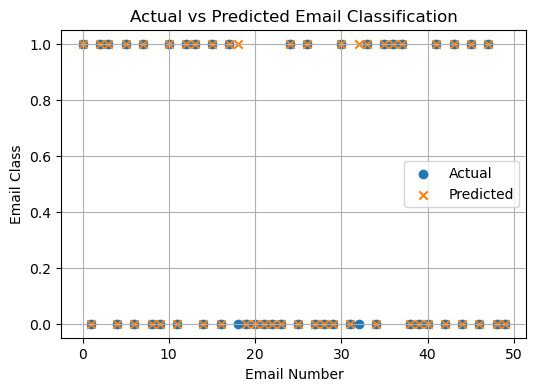

In [10]:
# Visualize actual and predicted email classes
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.scatter(range(50), y_test.iloc[:50], label="Actual", marker="o")
plt.scatter(range(50), y_pred[:50], label="Predicted", marker="x")

plt.xlabel("Email Number")
plt.ylabel("Email Class")
plt.title("Actual vs Predicted Email Classification")
plt.legend()
plt.grid(True)
plt.show()

# Practical 3: 
Phishing Email Classification using Naïve Bayes

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

In [12]:
df = pd.read_csv("03_phishing_email.csv")
df.head()

,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


In [13]:
X = df["text_combined"]
y = df["label"]

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [15]:
tfidf = TfidfVectorizer()
X_train = tfidf.fit_transform(X_train)
X_test = tfidf.transform(X_test)

In [16]:
# Train the Naïve Bayes model
model = MultinomialNB()
model.fit(X_train, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [17]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:",accuracy)
print("Accuracy percentage:",accuracy*100,"%")
print(classification_report(y_test, y_pred))

Accuracy: 0.9760577039641168
Accuracy percentage: 97.60577039641169 %
              precision    recall  f1-score   support

           0       0.96      0.99      0.98      7919
           1       0.99      0.96      0.98      8579

    accuracy                           0.98     16498
   macro avg       0.98      0.98      0.98     16498
weighted avg       0.98      0.98      0.98     16498



In [22]:
# predict one sample
print("Actual Label:", y_test.iloc[0])
print("Predicted Label:", y_pred[0])

Actual Label: 1
Predicted Label: 1


In [23]:
# predict a new email
email = ["Your account is blocked. Click here to verify your password."]
email_tfidf = tfidf.transform(email)
prediction = model.predict(email_tfidf)
print("Prediction:", prediction[0])

Prediction: 1


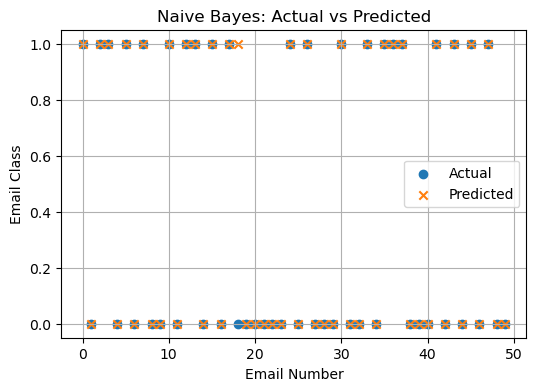

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.scatter(range(50), y_test.iloc[:50], label="Actual", marker="o")
plt.scatter(range(50), y_pred[:50], label="Predicted", marker="x")

plt.xlabel("Email Number")
plt.ylabel("Email Class")
plt.title("Naive Bayes: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.show()